# Food-101 Image Classification Using Deep Learning

**Datamites Internship – AI Project  |  Project ID: PRAICP-1009-101**

| | |
|---|---|
| **Domain** | AI / Computer Vision / Deep Learning |
| **Dataset** | Food-101 – 101,000 images, 101 food classes (1,000 images per class) |
| **Framework** | TensorFlow / Keras |


### Contents

1. Business Understanding
2. Environment Setup (Google Colab)
3. Dataset Loading
4. Exploratory Data Analysis
5. Data Preprocessing and Splitting
6. TensorFlow Data Pipeline
7. Baseline CNN
8. Transfer Learning with EfficientNetB0 – Phase 1 (Colab)
9. Resuming EfficientNetB0 Training on Kaggle
10. Fine-Tuning EfficientNetB0 (3 stages)
11. Final Evaluation of the Selected Model
12. Additional Experiments: EfficientNetV2B0 and MobileNetV2
13. Model Comparison and Final Selection
14. Limitations, Conclusion and Future Work

---

### How this notebook was run (please read)

Google Colab stopped the runtime (and auto-save failed) while EfficientNetB0 was being trained, so the project was completed on two platforms:

| Part | Sections | Platform | Work done |
|---|---|---|---|
| **A** | 2 – 8 | Google Colab, T4 GPU, TensorFlow 2.21 | data loading, EDA, split, baseline CNN, EfficientNetB0 head training |
| **B** | 9 – 13 | Kaggle, 2 × T4 GPU, TensorFlow 2.20 | resumed training from the saved checkpoint, fine-tuning, evaluation, extra experiments |

All outputs in this notebook are the **original recorded outputs** of those runs. Only repeated framework warning lines and intermediate Keras progress-bar lines were removed to keep the logs readable. File paths therefore differ between Part A (`/content/...`, Google Drive) and Part B (`/kaggle/...`).

---
# 1. Business Understanding

### Problem Statement
Develop a machine learning model that can classify the type of food from an input image.

### Project Objective
Build a deep learning image classification model capable of identifying food images across 101 different food categories.

### Methodology
1. Dataset loading and exploration
2. Image preprocessing and train / validation / test split
3. Baseline CNN development
4. Transfer learning with EfficientNetB0 (head training followed by fine-tuning)
5. Comparison with EfficientNetV2B0 and MobileNetV2
6. Final model selection and evaluation on the test set

### Expected Outcome
A trained image classification model that predicts the food category of an unseen image.

---
# 2. Environment Setup (Google Colab)

*Part A – Google Colab.* Check the Python / TensorFlow versions and confirm that a GPU is available.

In [ ]:
import tensorflow as tf
import sys

print("Python Version:", sys.version)
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

Python Version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Thu Oct 15 17:42:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

---
# 3. Dataset Loading

The Food-101 dataset contains images of 101 food categories. It is stored as a ZIP file in Google Drive.

**Steps**
1. Mount Google Drive.
2. Extract the ZIP file into the Colab runtime.
3. Verify the extracted class folders.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/PRAICP_1009_101_Food_classify/food-101.zip"
extract_path = "/content/food101"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extracted folders:", os.listdir(extract_path))

Dataset extracted successfully!
Extracted folders: ['lobster_roll_sandwich', 'tuna_tartare', 'crab_cakes', 'spaghetti_bolognese', 'pizza', 'oysters', 'baklava', 'club_sandwich', 'frozen_yogurt', 'apple_pie', 'caesar_salad', 'beet_salad', 'lobster_bisque', 'tacos', 'caprese_salad', 'chocolate_cake', 'ravioli', 'chicken_quesadilla', 'paella', 'cheese_plate', 'seaweed_salad', 'falafel', 'baby_back_ribs', 'bibimbap', 'hamburger', 'filet_mignon', 'nachos', 'macaroni_and_cheese', 'tiramisu', 'edamame', 'chicken_wings', 'lasagna', 'escargots', 'beef_carpaccio', 'poutine', 'macarons', 'deviled_eggs', 'prime_rib', 'ceviche', 'french_onion_soup', 'ice_cream', 'sashimi', 'bread_pudding', 'fried_rice', 'shrimp_and_grits', 'donuts', 'cannoli', 'scallops', 'hummus', 'churros', 'breakfast_burrito', 'chocolate_mousse', 'dumplings', 'spaghetti_carbonara', 'hot_and_sour_soup', 'beef_tartare', 'steak', 'grilled_salmon', 'sushi', 'garlic_bread', 'chicken_curry', 'bruschetta', 'french_toast', 'samosa', 'fi

---
# 4. Exploratory Data Analysis (EDA)

**Objective:** understand the dataset before building a model.

**EDA tasks:** number of classes and images, images per class, missing / empty classes, sample images, image dimensions.

### 4.1 Class and image counts

In [ ]:
import os
import pandas as pd

dataset_path = "/content/food101"

food_classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

class_counts = {}

for food in food_classes:
    folder_path = os.path.join(dataset_path, food)

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[food] = len(images)

df_counts = pd.DataFrame(
    class_counts.items(),
    columns=["Food_Class", "Image_Count"]
)

print("Total Food Classes:", len(food_classes))
print("Total Images:", df_counts["Image_Count"].sum())
print("Minimum Images:", df_counts["Image_Count"].min())
print("Maximum Images:", df_counts["Image_Count"].max())

display(df_counts.head(10))

Total Food Classes: 101
Total Images: 101000
Minimum Images: 1000
Maximum Images: 1000


,Food_Class,Image_Count
0,apple_pie,1000
1,baby_back_ribs,1000
2,baklava,1000
3,beef_carpaccio,1000
4,beef_tartare,1000
5,beet_salad,1000
6,beignets,1000
7,bibimbap,1000
8,bread_pudding,1000
9,breakfast_burrito,1000


### 4.2 Sample images

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

random.seed(42)

sample_classes = random.sample(food_classes, 9)

plt.figure(figsize=(12, 12))

for i, food in enumerate(sample_classes):
    folder_path = os.path.join(dataset_path, food)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_name = random.choice(image_files)
    image_path = os.path.join(folder_path, image_name)

    img = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(food.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

### 4.3 Image dimensions

In [ ]:
image_sizes = []

for food in sample_classes:
    folder_path = os.path.join(dataset_path, food)

    image_name = next(
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    image_path = os.path.join(folder_path, image_name)

    with Image.open(image_path) as img:
        image_sizes.append(img.size)

print("Sample Image Dimensions:")
print(image_sizes)

Sample Image Dimensions:
[(512, 512), (512, 384), (382, 512), (512, 512), (512, 512), (512, 512), (512, 384), (512, 512), (384, 512)]


### EDA Conclusion

- The dataset contains **101,000 images** in **101 classes**.
- Every class has exactly **1,000 images** – the dataset is perfectly balanced, so no oversampling / undersampling is needed.
- In the sample checked, images were up to 512 px on the longer side with varying aspect ratios (512×512, 512×384, 384×512), so they must be resized to one fixed size before training.

---
# 5. Data Preprocessing and Splitting

**Objective:** prepare the images for deep learning.

1. Split the data into **training (70 %)**, **validation (15 %)** and **test (15 %)** sets using stratified sampling (`random_state=42`), so each class appears in the same proportion in every set.
2. Resize images to **224 × 224** and convert them to RGB.
3. Shuffle the training data and load images in batches to limit memory use.

**Data-leakage prevention:** the test set is kept separate from training and validation and is used only for the final evaluation.

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

image_paths = []
labels = []

for food in food_classes:
    folder_path = os.path.join(dataset_path, food)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder_path, filename))
            labels.append(food)

df_images = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

train_df, temp_df = train_test_split(
    df_images,
    test_size=0.30,
    stratify=df_images["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

Training Images: 70700
Validation Images: 15150
Testing Images: 15150


In [ ]:
df_images.head()

,image_path,label
0,/content/food101/apple_pie/812047.jpg,apple_pie
1,/content/food101/apple_pie/2598068.jpg,apple_pie
2,/content/food101/apple_pie/591398.jpg,apple_pie
3,/content/food101/apple_pie/2084963.jpg,apple_pie
4,/content/food101/apple_pie/532974.jpg,apple_pie


In [ ]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining class counts:")
print(train_df["label"].value_counts().head())

print("\nValidation class counts:")
print(val_df["label"].value_counts().head())

print("\nTesting class counts:")
print(test_df["label"].value_counts().head())

Training: (70700, 2)
Validation: (15150, 2)
Testing: (15150, 2)

Training class counts:
label
chicken_wings    700
gyoza            700
beignets         700
clam_chowder     700
escargots        700
Name: count, dtype: int64

Validation class counts:
label
spaghetti_bolognese    150
caesar_salad           150
dumplings              150
fried_rice             150
eggs_benedict          150
Name: count, dtype: int64

Testing class counts:
label
caprese_salad    150
ravioli          150
beet_salad       150
tiramisu         150
garlic_bread     150
Name: count, dtype: int64


---
# 6. TensorFlow Data Pipeline

Convert the three splits into `tf.data` datasets:
encode class names as integers → read and decode each JPEG → resize to 224 × 224 (RGB) → batch (32) → prefetch for faster GPU feeding.
Pixel values are kept in the 0–255 range; each model rescales / preprocesses them internally.

In [ ]:
import tensorflow as tf

class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

train_df["label_id"] = train_df["label"].map(class_to_index)
val_df["label_id"] = val_df["label"].map(class_to_index)
test_df["label_id"] = test_df["label"].map(class_to_index)

num_classes = len(class_names)

print("Number of Classes:", num_classes)
print("First 5 Classes:", class_names[:5])
print(train_df[["label", "label_id"]].head())

Number of Classes: 101
First 5 Classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']
               label  label_id
20274  chicken_wings        20
52529          gyoza        52
6444        beignets         6
24917   clam_chowder        24
35440      escargots        35


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, label

In [ ]:
def create_dataset(df, training=False):

    paths = df["image_path"].values
    labels = df["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [ ]:
for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Pixel Range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Image Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32,)
Pixel Range: 0.0 255.0


---
# 7. Baseline CNN

**Objective:** build a simple CNN from scratch to set a reference performance level.

### Architecture
Input 224×224×3 → Rescaling (÷255) → 4 × [Conv2D (32 / 64 / 128 / 256 filters, 3×3, ReLU) + MaxPooling] → GlobalAveragePooling → Dense(128, ReLU) → Dropout(0.3) → Dense(101, Softmax)

### Training configuration
Optimizer Adam (lr 0.001) · loss sparse categorical cross-entropy · metric accuracy · batch size 32 · up to 10 epochs with EarlyStopping on validation loss (patience 2).

In [ ]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(101, activation="softmax")

])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 101)            │        13,029 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 434,341 (1.66 MB)

Trainable params: 434,341 (1.66 MB)

Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 181s 79ms/step - accuracy: 0.0196 - loss: 4.5270 - val_accuracy: 0.0401 - val_loss: 4.3532
Epoch 2/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 151s 68ms/step - accuracy: 0.0506 - loss: 4.2486 - val_accuracy: 0.0745 - val_loss: 4.0673
Epoch 3/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 152s 69ms/step - accuracy: 0.0879 - loss: 3.9705 - val_accuracy: 0.1334 - val_loss: 3.7238
Epoch 4/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 221s 78ms/step - accuracy: 0.1300 - loss: 3.7274 - val_accuracy: 0.1670 - val_loss: 3.5276
Epoch 5/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 172s 78ms/step - accuracy: 0.1626 - loss: 3.5460 - val_accuracy: 0.1991 - val_loss: 3.3621
Epoch 6/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 183s 69ms/step - accuracy: 0.1913 - loss: 3.3958 - val_accuracy: 0.2142 - val_loss: 3.2787
Epoch 7/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 172s 78ms/step - accuracy: 0.2171 - loss: 3.2635 - val_accuracy: 0.2424 - val_loss: 3.1452
Epoch 8/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 153s 69ms/step - accuracy: 

### Baseline results

| Metric | Value |
|---|---:|
| Final training accuracy | 27.68 % |
| Final validation accuracy | 29.76 % |
| Final training loss | 2.9503 |
| Final validation loss | 2.8823 |

**Observations**
- Accuracy rose and loss fell in every epoch, and training and validation accuracy stayed close together – there is no sign of overfitting.
- The model was still improving when the 10 epochs ended, but at 29.76 % it is far from useful: learning 101 food classes from scratch needs far more capacity, data and training time.
- This motivates **transfer learning**, which re-uses features already learned on ImageNet.

In [ ]:
import os

save_dir = "/content/drive/MyDrive/Food101_Project"
os.makedirs(save_dir, exist_ok=True)

cnn_model.save(
    os.path.join(save_dir, "food101_baseline_cnn.keras")
)

print("Baseline CNN model saved successfully!")

Baseline CNN model saved successfully!


---
# 8. Transfer Learning with EfficientNetB0 – Phase 1 (Colab)

**Objective:** improve on the baseline by using EfficientNetB0 pre-trained on ImageNet.

**Why transfer learning?** The baseline CNN reached only 29.76 % validation accuracy. EfficientNetB0 already knows general visual features (edges, textures, shapes, object parts), so only a new classification head has to be learned for the 101 food classes.

**Phase 1 method**
1. Load EfficientNetB0 with ImageNet weights and without its original classifier (`include_top=False`).
2. **Freeze** the pre-trained backbone.
3. Add a new head: GlobalAveragePooling → Dense(256, ReLU) → Dropout(0.3) → Dense(101, Softmax).
4. Compile with Adam (lr 0.001) and train; a `ModelCheckpoint` saves the model with the best validation accuracy to Google Drive.

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Model

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully!")

EfficientNetB0 loaded successfully!


In [ ]:
num_classes = 101
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

efficientnet_model = Model(
    inputs=inputs,
    outputs=outputs
)

efficientnet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 101)            │        25,957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 4,403,464 (16.80 MB)

Trainable params: 353,893 (1.35 MB)

Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled successfully!")

EfficientNetB0 compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/Food101_Project/best_efficientnet.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop_eff = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        checkpoint,
        early_stop_eff
    ]
)

Epoch 1/5
Epoch 1: val_accuracy improved from None to 0.63987, saving model to /content/drive/MyDrive/Food101_Project/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 237s 93ms/step - accuracy: 0.5141 - loss: 1.9244 - val_accuracy: 0.6399 - val_loss: 1.3777
Epoch 2/5
Epoch 2: val_accuracy improved from 0.63987 to 0.65789, saving model to /content/drive/MyDrive/Food101_Project/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 174s 79ms/step - accuracy: 0.6162 - loss: 1.4501 - val_accuracy: 0.6579 - val_loss: 1.3022
Epoch 3/5
Epoch 3: val_accuracy improved from 0.65789 to 0.66515, saving model to /content/drive/MyDrive/Food101_Project/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 143s 65ms/step - accuracy: 0.6506 - loss: 1.3058 - val_accuracy: 0.6651 - val_loss: 1.2659
Epoch 4/5
Epoch 4: val_accuracy improved from 0.66515 to 0.66627, saving model to /content/drive/MyDrive/Food101_Project/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 153s 69ms/step - accuracy:

### Colab interruption and hand-over to Kaggle

While this model was training, the Colab runtime stopped and the notebook's auto-save failed. The checkpoint `best_efficientnet.keras`, written to Google Drive by `ModelCheckpoint`, survived. It was uploaded to Kaggle (which offers a free GPU) as a model input, and training was **resumed from epoch 4** – see Part B below.

---
# 9. Resuming EfficientNetB0 Training on Kaggle

*Part B – Kaggle (2 × Tesla T4, TensorFlow 2.20).*

### 9.1 Environment check

In [ ]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 9.2 Re-creating the data split and pipeline

The Food-101 images were added to Kaggle as a dataset. The same recipe as in Section 5 is used: the same 70 / 15 / 15 stratified split with `random_state=42`, 224 × 224 images, batch size 32.

> **Note:** the file list is built in sorted order here, whereas Colab used `os.listdir` order, so the Kaggle split is not guaranteed to be identical to the Colab split. See *Limitations* in Section 14.

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Find Food-101 image folders
dataset_path = None

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    if "apple_pie" in dirs and "pizza" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError("Food-101 image folders not found.")

print("Dataset:", dataset_path)

# 2. Collect images and labels
classes = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])

paths = []
labels = []

for i, food in enumerate(classes):
    folder = os.path.join(dataset_path, food)

    for file in sorted(os.listdir(folder)):
        if file.lower().endswith((".jpg", ".jpeg")):
            paths.append(os.path.join(folder, file))
            labels.append(i)

paths = np.array(paths)
labels = np.array(labels)

# 3. Split dataset
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))

# 4. TensorFlow preprocessing
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    return tf.cast(image, tf.float32), label

def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(paths), seed=42)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(X_train, y_train, True)
val_ds = create_dataset(X_val, y_val)

print("TensorFlow datasets ready!")

Dataset: /kaggle/input/datasets/goldking1980/food-dataset
Training images: 70700
Validation images: 15150
Test images: 15150
TensorFlow datasets ready!


### 9.3 Loading the saved EfficientNetB0 checkpoint

In [ ]:
import tensorflow as tf
import os

model_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".keras"):
            model_files.append(os.path.join(root, file))

print("Found models:", model_files)

if len(model_files) == 1:
    efficientnet_model = tf.keras.models.load_model(
        model_files[0]
    )
    print("EfficientNetB0 loaded successfully!")
else:
    print("Check model attachment or select the correct model.")

Found models: ['/kaggle/input/models/goldking1980/food101-efficientnetb0/tensorflow2/default/1/best_efficientnet.keras']
EfficientNetB0 loaded successfully!


### 9.4 Resuming head training (epochs 4 – 10)

Training continues with `initial_epoch=3`, so the log starts at epoch 4. The backbone is still frozen; only the new head is trained.

In [ ]:
# 1. Save best checkpoint
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# 2. Resume training from epoch 4
history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=3,
    epochs=10,
    callbacks=[checkpoint]
)

# 3. Save final model
efficientnet_model.save(
    "/kaggle/working/food101_efficientnet_final.keras"
)

print("Training completed. Model saved!")

Epoch 4/10
Epoch 4: val_accuracy improved from None to 0.73644, saving model to /kaggle/working/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 222s 88ms/step - accuracy: 0.6730 - loss: 1.2223 - val_accuracy: 0.7364 - val_loss: 0.9726
Epoch 5/10
Epoch 5: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.6917 - loss: 1.1288 - val_accuracy: 0.7267 - val_loss: 1.0122
Epoch 6/10
Epoch 6: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.7031 - loss: 1.0735 - val_accuracy: 0.7200 - val_loss: 1.0467
Epoch 7/10
Epoch 7: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.7150 - loss: 1.0235 - val_accuracy: 0.7217 - val_loss: 1.0526
Epoch 8/10
Epoch 8: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.7234 - loss: 0.9809 - val_accuracy: 0.7173 - val_loss: 1.0760
Epoch 9/10
Epoch 9: val_ac

**Result:** the best validation accuracy was **73.64 % at epoch 4** (model saved). In epochs 5 – 10 validation accuracy fell back to about 71 – 73 % while validation loss kept rising, i.e. the frozen-backbone head had reached its limit. The next step is therefore **fine-tuning** part of the backbone.

---
# 10. Fine-Tuning EfficientNetB0

**Idea:** unfreeze the top layers of the pre-trained backbone so that its high-level features adapt to food images, using a very small learning rate to avoid destroying the pre-trained weights. All `BatchNormalization` layers stay frozen.

| Stage | Backbone layers made trainable | Learning rate | Epochs | Best val. accuracy |
|---|---|---:|---|---:|
| 1 | last 20 | 1e-5 | 1 – 5 | 77.38 % |
| 2 | (same, continued) | 5e-6 | 6 – 15 | 77.87 % |
| 3 | last 50 | 2e-6 | 10 | **78.17 %** |

Callbacks: `ModelCheckpoint` (monitor `val_accuracy`; `initial_value_threshold` set to the previous best so the saved file is only replaced when the model really improves), `EarlyStopping` on `val_loss`, and `ReduceLROnPlateau` in stages 1 – 2.

### 10.1 Load the best head-trained model and locate the backbone

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_efficientnet.keras"
)

print("Model loaded successfully!")

for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

Model loaded successfully!
0 input_layer_2 InputLayer
1 efficientnetb0 Functional
2 global_average_pooling2d_1 GlobalAveragePooling2D
3 dense_1 Dense
4 dropout_1 Dropout
5 dense_2 Dense


### 10.2 Stage 1 – unfreeze the last 20 backbone layers (lr = 1e-5)

In [ ]:
# Locate the EfficientNetB0 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "efficientnet" in layer.name.lower()
)

# Enable fine-tuning
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable backbone layers: 15


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")

Fine-tuning model compiled successfully!


In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.7364,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5
Epoch 1: val_accuracy improved from 0.73640 to 0.76106, saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 143s 56ms/step - accuracy: 0.7243 - loss: 1.0006 - val_accuracy: 0.7611 - val_loss: 0.8932 - learning_rate: 1.0000e-05
Epoch 2/5
Epoch 2: val_accuracy improved from 0.76106 to 0.76495, saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 102s 46ms/step - accuracy: 0.7372 - loss: 0.9455 - val_accuracy: 0.7650 - val_loss: 0.8771 - learning_rate: 1.0000e-05
Epoch 3/5
Epoch 3: val_accuracy improved from 0.76495 to 0.76845, saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7482 - loss: 0.9120 - val_accuracy: 0.7684 - val_loss: 0.8648 - learning_rate: 1.0000e-05
Epoch 4/5
Epoch 4: val_accuracy improved from 0.76845 to 0.77003, saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━

### 10.3 Stage 2 – continue with a smaller learning rate (lr = 5e-6, epochs 6 – 15)

Validation accuracy was still creeping upward at the end of Stage 1, so training continues from the best Stage 1 model with the learning rate halved.

In [ ]:
import tensorflow as tf

# 1. Load the best fine-tuned model
model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_efficientnet.keras"
)

# 2. Compile with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Save only if validation accuracy improves
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.7738,
    verbose=1
)

# 4. Stop if validation loss stops improving
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# 5. Reduce learning rate if necessary
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# 6. Continue from epoch 6 to epoch 15
history_extended = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=5,
    epochs=15,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

print("Extended fine-tuning completed!")

Epoch 6/15
Epoch 6: val_accuracy did not improve from 0.77380
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 142s 55ms/step - accuracy: 0.7654 - loss: 0.8400 - val_accuracy: 0.7735 - val_loss: 0.8456 - learning_rate: 5.0000e-06
Epoch 7/15
Epoch 7: val_accuracy did not improve from 0.77380
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7696 - loss: 0.8245 - val_accuracy: 0.7732 - val_loss: 0.8418 - learning_rate: 5.0000e-06
Epoch 8/15
Epoch 8: val_accuracy improved from 0.77380 to 0.77571, saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7717 - loss: 0.8138 - val_accuracy: 0.7757 - val_loss: 0.8391 - learning_rate: 5.0000e-06
Epoch 9/15
Epoch 9: val_accuracy did not improve from 0.77571
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 100s 45ms/step - accuracy: 0.7733 - loss: 0.8113 - val_accuracy: 0.7754 - val_loss: 0.8373 - learning_rate: 5.0000e-06
Epoch 10/15
Epoch 10: val_accuracy improved from 0.77571 to 0.77591, saving model

### 10.4 Stage 3 – unfreeze the last 50 backbone layers (lr = 2e-6)

The best Stage 2 model is reloaded, the freezing rule is re-applied to the last 50 backbone layers (BatchNormalization still frozen), and training continues for up to 10 more epochs with a very small learning rate. The best model is saved as `best_finetuned_stage3.keras`.

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_efficientnet.keras"
)

base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "efficientnet" in layer.name.lower()
)

base_model.trainable = True

# Freeze all but the last 50 backbone layers
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Keep BatchNormalization frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable backbone layers: 15


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_stage3.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.77875,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_stage3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/10
Epoch 1: val_accuracy did not improve from 0.77875
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 142s 55ms/step - accuracy: 0.7863 - loss: 0.7550 - val_accuracy: 0.7784 - val_loss: 0.8264
Epoch 2/10
Epoch 2: val_accuracy improved from 0.77875 to 0.77974, saving model to /kaggle/working/best_finetuned_stage3.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 102s 46ms/step - accuracy: 0.7873 - loss: 0.7497 - val_accuracy: 0.7797 - val_loss: 0.8268
Epoch 3/10
Epoch 3: val_accuracy improved from 0.77974 to 0.77987, saving model to /kaggle/working/best_finetuned_stage3.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7862 - loss: 0.7523 - val_accuracy: 0.7799 - val_loss: 0.8254
Epoch 4/10
Epoch 4: val_accuracy did not improve from 0.77987
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 100s 45ms/step - accuracy: 0.7878 - loss: 0.7456 - val_accuracy: 0.7795 - val_loss: 0.8251
Epoch 5/10
Epoch 5: val_accuracy did not improve from 0.77987
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 100s 45ms/step - accuracy: 0.7894 - loss:

**Result:** validation accuracy improved slowly but steadily to **78.17 %**. The gains are shrinking (+0.5 points in Stage 2, +0.3 in Stage 3), which indicates the model is close to convergence for this setup.

---
# 11. Final Evaluation of the Selected Model

### 11.1 Validation performance
The best Stage 3 checkpoint is loaded, evaluated on the validation set and saved as the final model (`food101_final_model.keras`).

In [ ]:
import tensorflow as tf

# Load the best Stage 3 model
final_model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_stage3.keras"
)

# Evaluate on validation data
val_loss, val_accuracy = final_model.evaluate(
    val_ds,
    verbose=1
)

print(f"Final Validation Accuracy: {val_accuracy:.2%}")
print(f"Final Validation Loss: {val_loss:.4f}")

# Save final selected model
final_model.save(
    "/kaggle/working/food101_final_model.keras"
)

print("Final model saved successfully!")

474/474 ━━━━━━━━━━━━━━━━━━━━ 31s 48ms/step - accuracy: 0.7817 - loss: 0.8219
Final Validation Accuracy: 78.17%
Final Validation Loss: 0.8219
Final model saved successfully!


### 11.2 Test performance
The test set is evaluated with the final model.

In [ ]:
# Create test dataset from the existing test split
test_ds = create_dataset(
    X_test,
    y_test,
    training=False
)

print("Test dataset ready!")
print("Total test images:", len(X_test))

Test dataset ready!
Total test images: 15150


In [ ]:
import tensorflow as tf

final_model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_stage3.keras"
)

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

474/474 ━━━━━━━━━━━━━━━━━━━━ 50s 89ms/step - accuracy: 0.7800 - loss: 0.8093
Test Accuracy: 78.00%
Test Loss: 0.8093


### 11.3 Per-class precision, recall and F1-score (test set)

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

predictions = final_model.predict(test_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))

474/474 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step
                         precision    recall  f1-score   support

              apple_pie     0.6738    0.6333    0.6529       150
         baby_back_ribs     0.7278    0.7667    0.7468       150
                baklava     0.8725    0.8667    0.8696       150
         beef_carpaccio     0.7516    0.7867    0.7687       150
           beef_tartare     0.7660    0.7200    0.7423       150
             beet_salad     0.6863    0.7000    0.6931       150
               beignets     0.8457    0.9133    0.8782       150
               bibimbap     0.9091    0.9333    0.9211       150
          bread_pudding     0.5882    0.6000    0.5941       150
      breakfast_burrito     0.6883    0.7067    0.6974       150
             bruschetta     0.5732    0.6267    0.5987       150
           caesar_salad     0.7643    0.8000    0.7818       150
                cannoli     0.8603    0.7800    0.8182       150
          caprese_salad     0.7467    0.7467  

### 11.4 Confusion matrix (test set)

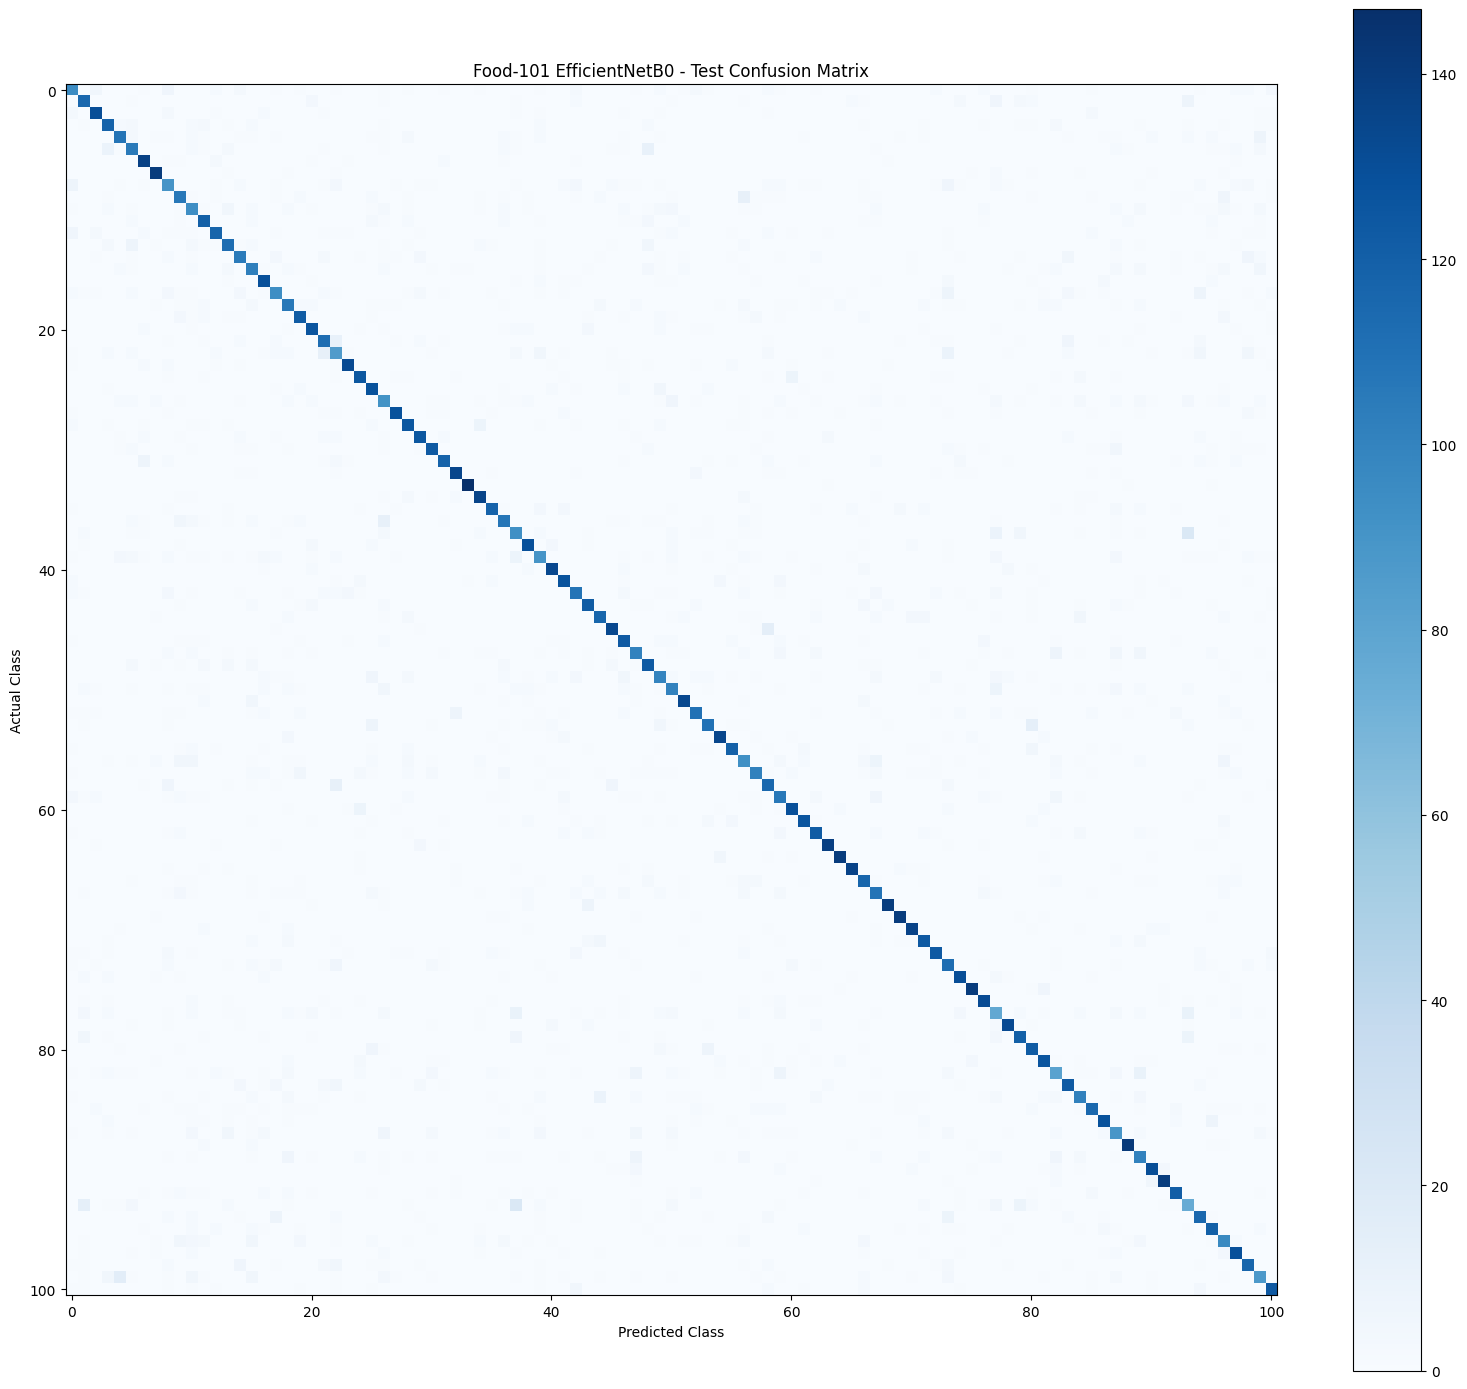

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))
plt.imshow(cm, cmap="Blues")
plt.title("Food-101 EfficientNetB0 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()
plt.tight_layout()
plt.show()

### 11.5 Final results

| Metric (test set, 15,150 images) | Value |
|---|---:|
| Accuracy | **78.00 %** |
| Macro precision | 78.14 % |
| Macro recall | 78.00 % |
| Macro F1-score | 78.00 % |
| Weighted F1-score | 78.00 % |
| Test loss | 0.8093 |

| Easiest classes | F1-score |
|---|---:|
| edamame | 98.33 % |
| onion rings | 94.24 % |
| seaweed salad | 94.00 % |
| miso soup | 93.96 % |
| spaghetti carbonara | 92.98 % |

| Hardest classes | F1-score |
|---|---:|
| pork chop | 51.85 % |
| steak | 51.90 % |
| chocolate mousse | 55.92 % |
| ravioli | 57.45 % |
| scallops | 58.75 % |

**Interpretation**
- The confusion matrix has a strong diagonal – most images are classified correctly.
- Classes with a distinctive look (edamame, onion rings, seaweed salad, miso soup) are recognised best.
- Meat dishes and desserts with a similar appearance (pork chop, steak, chocolate mousse) and a few others (ravioli, scallops) are the hardest, probably because many Food-101 classes look alike; the confusion matrix can be used to check which pairs are mixed up.

---
# 12. Additional Experiments: EfficientNetV2B0 and MobileNetV2

**Objective:** check whether another pre-trained architecture could beat EfficientNetB0.

Both models were trained in a separate Kaggle session on the **same 70 / 15 / 15 split** (Section 9.2: sorted file list, `random_state=42`; the datasets `train_ds`, `val_ds`, `test_ds` were re-created there with identical code logic). For both models:

- ImageNet weights, frozen backbone, new head (GlobalAveragePooling → Dense(256) → Dropout → Dense(101, softmax))
- data augmentation during training: random horizontal flip, rotation (factor 0.08), zoom (0.10) and contrast (0.10)
- Adam, lr 0.001, up to 10 epochs, `ModelCheckpoint` + `EarlyStopping` on `val_accuracy` (patience 3)

These two models were trained with the frozen backbone only (no fine-tuning stage); the experiments were stopped when they did not approach the EfficientNetB0 result.

### 12.1 EfficientNetV2B0

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# 1. Create data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="food_augmentation")

# 2. Load pretrained EfficientNetV2B0
base_model_v2 = tf.keras.applications.EfficientNetV2B0(
    weights="imagenet",
    include_top=False,
    include_preprocessing=True,
    input_shape=(224, 224, 3)
)

# 3. Freeze the pretrained backbone
base_model_v2.trainable = False

# 4. Create input layer
inputs = layers.Input(shape=(224, 224, 3))

# 5. Apply augmentation
x = data_augmentation(inputs)

# 6. Extract features
x = base_model_v2(x, training=False)

# 7. Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

# 8. Output layer
outputs = layers.Dense(
    101,
    activation="softmax"
)(x)

# 9. Build final model
model_v2 = Model(inputs, outputs)

print("EfficientNetV2B0 model created successfully!")

EfficientNetV2B0 model created successfully!


In [ ]:
# Compile the model
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best model
checkpoint_v2 = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_efficientnetv2b0.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# Stop training if accuracy stops improving
early_stop_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint_v2,
        early_stop_v2
    ]
)

Epoch 1/10
Epoch 1: val_accuracy improved from None to 0.61617, saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 186s 77ms/step - accuracy: 0.4498 - loss: 2.1975 - val_accuracy: 0.6162 - val_loss: 1.4357
Epoch 2/10
Epoch 2: val_accuracy improved from 0.61617 to 0.63861, saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 168s 76ms/step - accuracy: 0.5469 - loss: 1.7402 - val_accuracy: 0.6386 - val_loss: 1.3571
Epoch 3/10
Epoch 3: val_accuracy improved from 0.63861 to 0.64983, saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 167s 76ms/step - accuracy: 0.5733 - loss: 1.6252 - val_accuracy: 0.6498 - val_loss: 1.3164
Epoch 4/10
Epoch 4: val_accuracy improved from 0.64983 to 0.65921, saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 167s 76ms/step - accuracy: 0.5914 - loss: 1.5476 - val_accuracy: 0.6592 - val_loss: 1.2849
Epoch 5

**Result:** best validation accuracy **67.13 %** (epoch 9); validation accuracy was flattening at about 67 %, clearly below EfficientNetB0.

### 12.2 MobileNetV2

MobileNetV2 expects inputs in the range [-1, 1], so a `Rescaling(1/127.5, offset=-1)` layer is added before the backbone, and dropout is increased to 0.4.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Confirm datasets are available
assert "train_ds" in globals(), "train_ds is missing"
assert "val_ds" in globals(), "val_ds is missing"

# Data augmentation
augmentation_mobile = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="mobilenet_augmentation")

# Load ImageNet-pretrained MobileNetV2
base_mobile = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone
base_mobile.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = augmentation_mobile(inputs)

# MobileNetV2 requires inputs in [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_mobile(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    101,
    activation="softmax"
)(x)

model_mobile = Model(inputs, outputs)

print("MobileNetV2 created successfully!")

MobileNetV2 created successfully!


In [ ]:
model_mobile.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_mobile = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_mobilenetv2.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop_mobile = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_mobile = model_mobile.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint_mobile,
        early_stop_mobile
    ]
)

Epoch 1/10
Epoch 1: val_accuracy improved from None to 0.50185, saving model to /kaggle/working/best_mobilenetv2.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 158s 69ms/step - accuracy: 0.3455 - loss: 2.6942 - val_accuracy: 0.5018 - val_loss: 1.9728
Epoch 2/10
Epoch 2: val_accuracy improved from 0.50185 to 0.51571, saving model to /kaggle/working/best_mobilenetv2.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 151s 68ms/step - accuracy: 0.4388 - loss: 2.2374 - val_accuracy: 0.5157 - val_loss: 1.8978
Epoch 3/10
Epoch 3: val_accuracy improved from 0.51571 to 0.53729, saving model to /kaggle/working/best_mobilenetv2.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 150s 68ms/step - accuracy: 0.4548 - loss: 2.1551 - val_accuracy: 0.5373 - val_loss: 1.8104
Epoch 4/10
Epoch 4: val_accuracy did not improve from 0.53729
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 150s 68ms/step - accuracy: 0.4679 - loss: 2.0962 - val_accuracy: 0.5286 - val_loss: 1.8583
Epoch 5/10
Epoch 5: val_accuracy did not improve from 0.53729
2210/2210 ━━━━━━━━━━━━━━━

**Result:** best validation accuracy **55.01 %** (epoch 9) – the weakest of the pre-trained models, which is expected from a small, speed-oriented network.

---
# 13. Model Comparison and Final Selection

| Model | Training setup | Best validation accuracy |
|---|---|---:|
| Baseline CNN | from scratch, 10 epochs | 29.76 % |
| MobileNetV2 | frozen backbone, augmentation, 10 epochs | 55.01 % |
| EfficientNetV2B0 | frozen backbone, augmentation, 10 epochs | 67.13 % |
| EfficientNetB0 – head training | frozen backbone | 73.64 % |
| **EfficientNetB0 – fine-tuned (3 stages)** | **last 20 → 50 layers unfrozen, lr 1e-5 → 2e-6** | **78.17 %** |

The charts below are drawn from the validation accuracies printed in the training logs above.

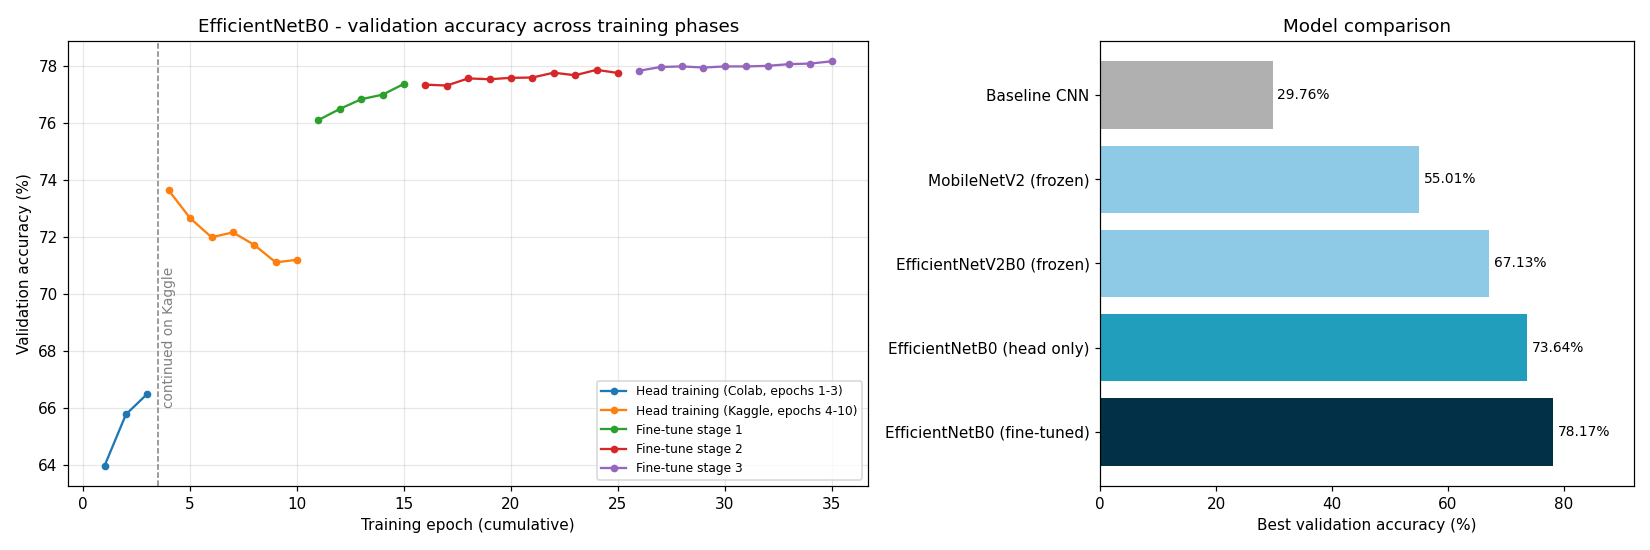

In [ ]:
import matplotlib.pyplot as plt

# Validation accuracy (%) per epoch, copied from the training logs above
phases = [
    ("Head training (Colab, epochs 1-3)", [63.99, 65.79, 66.51]),
    ("Head training (Kaggle, epochs 4-10)", [73.64, 72.67, 72.0, 72.17, 71.73, 71.12, 71.21]),
    ("Fine-tune stage 1", [76.11, 76.5, 76.84, 77.0, 77.38]),
    ("Fine-tune stage 2", [77.35, 77.32, 77.57, 77.54, 77.59, 77.6, 77.77, 77.68, 77.87, 77.76]),
    ("Fine-tune stage 3", [77.84, 77.97, 77.99, 77.95, 77.99, 77.99, 78.01, 78.07, 78.09, 78.17]),
]
models = {
    "Baseline CNN": 29.76,
    "MobileNetV2 (frozen)": 55.01,
    "EfficientNetV2B0 (frozen)": 67.13,
    "EfficientNetB0 (head only)": 73.64,
    "EfficientNetB0 (fine-tuned)": 78.17,
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})

# Left: EfficientNetB0 validation accuracy across all training phases
x0 = 1
for label, values in phases:
    xs = list(range(x0, x0 + len(values)))
    ax1.plot(xs, values, marker="o", markersize=4, label=label)
    x0 += len(values)
ax1.axvline(3.5, color="grey", linestyle="--", linewidth=1)
ax1.text(3.7, 66, "continued on Kaggle", rotation=90, color="grey", va="bottom", fontsize=9)
ax1.set_title("EfficientNetB0 - validation accuracy across training phases")
ax1.set_xlabel("Training epoch (cumulative)")
ax1.set_ylabel("Validation accuracy (%)")
ax1.grid(alpha=0.3)
ax1.legend(loc="lower right", fontsize=8)

# Right: best validation accuracy of every model
names, scores = list(models.keys()), list(models.values())
colors = ["#b0b0b0", "#8ecae6", "#8ecae6", "#219ebc", "#023047"]
bars = ax2.barh(names, scores, color=colors)
for bar, s in zip(bars, scores):
    ax2.text(s + 0.8, bar.get_y() + bar.get_height() / 2, f"{s:.2f}%", va="center", fontsize=9)
ax2.set_xlim(0, 92)
ax2.set_xlabel("Best validation accuracy (%)")
ax2.set_title("Model comparison")
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

### Final model selection

**Selected model: EfficientNetB0 – fine-tuned (Stage 3 checkpoint, saved as `food101_final_model.keras`).**

Reasons
- Highest validation accuracy of all models (**78.17 %**) and a matching **78.00 %** on the test set – validation and test results agree, so the model is not tuned to one split.
- Under the same head-only setup it was clearly ahead of EfficientNetV2B0 (67.13 %) and MobileNetV2 (55.01 %), and it improved a further ≈ 4.5 points through progressive fine-tuning.
- It is small (≈ 4.4 M parameters), so it is practical to deploy.

EfficientNetV2B0 and MobileNetV2 were trained with a frozen backbone only; with the same fine-tuning effort they might close part of the gap, but they were not pursued further.

---
# 14. Limitations, Conclusion and Future Work

### Limitations

**Split consistency between Colab and Kaggle.** The initial training (Sections 5 – 8) was done in Google Colab and the later training and evaluation (Sections 9 – 13) in Kaggle, where the data split was re-created. Colab built its file list with `os.listdir` and Kaggle with a sorted list, so the two splits may not be identical. Some Kaggle validation / test images may therefore have been seen during the first (Colab) epochs. The reported validation (78.17 %) and test (78.00 %) accuracies should therefore be read as *indicative* and cannot be confirmed as a fully independent hold-out result.

**Other limitations**
- EfficientNetB0 head training used no data augmentation (augmentation was used only in the EfficientNetV2B0 / MobileNetV2 experiments).
- EfficientNetV2B0 and MobileNetV2 were not fine-tuned, so the comparison with the fine-tuned EfficientNetB0 is not fully like-for-like.
- Images were resized to 224 × 224 only; higher resolutions typically help fine-grained food recognition.

### Conclusion

A baseline CNN trained from scratch reached 29.76 % validation accuracy on Food-101. Transfer learning with EfficientNetB0 raised this to 73.64 %, and three stages of careful fine-tuning with very small learning rates brought it to **78.17 % validation and 78.00 % test accuracy** – an improvement of about 48 percentage points over the baseline. Alternative architectures (EfficientNetV2B0, MobileNetV2) did not beat it in the experiments carried out, so EfficientNetB0 was selected as the final model.

### Future improvements
- Re-run the whole pipeline on a single platform with one fixed, saved split to obtain a verified independent test score.
- Add data augmentation (flip, rotation, zoom, colour jitter) to the EfficientNetB0 training, and try label smoothing and mixup / cutmix.
- Fine-tune EfficientNetV2B0 and larger EfficientNet variants at higher resolution (e.g. 260 – 300 px).
- Deploy the model as a Streamlit or FastAPI web app that classifies an uploaded food photo.

### Saved model files

| File | Content |
|---|---|
| `food101_baseline_cnn.keras` | baseline CNN |
| `best_efficientnet.keras` | EfficientNetB0 after head training (best epoch) |
| `best_finetuned_efficientnet.keras` | EfficientNetB0 after fine-tuning stages 1 – 2 |
| `best_finetuned_stage3.keras` | best EfficientNetB0 after stage 3 |
| `food101_final_model.keras` | **final selected model** |

| **Final model** | EfficientNetB0 (ImageNet transfer learning + 3-stage fine-tuning) |
| **Final result** | **78.17 % validation accuracy  ·  78.00 % test accuracy** |

---

### Results at a glance

| # | Model / stage | Best validation accuracy |
|---|---|---:|
| 1 | Baseline CNN (trained from scratch, 10 epochs) | 29.76 % |
| 2 | EfficientNetB0 – transfer learning (frozen backbone, new head) | 73.64 % |
| 3 | EfficientNetB0 – fine-tuning, Stage 1 (last 20 layers, lr 1e-5) | 77.38 % |
| 4 | EfficientNetB0 – fine-tuning, Stage 2 (lr 5e-6) | 77.87 % |
| 5 | **EfficientNetB0 – fine-tuning, Stage 3 (lr 2e-6)  ➜  selected model** | **78.17 %** |
| 6 | EfficientNetV2B0 – frozen backbone (experiment) | 67.13 % |
| 7 | MobileNetV2 – frozen backbone (experiment) | 55.01 % |

**Final test accuracy of the selected model: 78.00 %** (macro precision 78.14 %, macro recall 78.00 %, macro F1 78.00 %).

---